# 07 — Interpretação da HMM-LSTM com SHAP

O objetivo aqui é descrever o que a rede usa para prever o retorno. Não é provar relações
causais no mercado (Lundberg; Lee, 2017; Janzing; Minorics; Blöbaum, 2020). Os valores
SHAP dividem cada previsão entre as entradas, tomando como referência uma amostra do
treino. Em uma LSTM, cada entrada é uma variável em uma defasagem. Por isso, as
contribuições são somadas por variável, por grupo e por faixa de defasagem.

Usamos o `GradientExplainer` (gradientes esperados) com o dropout desligado, ou seja, a
previsão central da rede. As janelas são duas, com o mesmo protocolo do experimento:

- **14**: teste de out/2019 a mar/2020, com a entrada da Covid;
- **20**: teste de set/2022 a mar/2023, um período sem crise aguda.

O modelo retreinado precisa reproduzir as previsões salvas pelo experimento. Isso garante
que estamos explicando a mesma rede que foi avaliada.

In [1]:
import json
import logging
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import torch
import yaml
from torch import nn

logging.getLogger("hmmlearn").setLevel(logging.ERROR)  # avisos de convergência do Baum-Welch
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data.features import get_b3_trading_days
from src.data.risk_dataset import build_risk_split_dataset, make_risk_walk_forward_splits
from src.models.lstm import TrainingConfig, fit_lstm
from src.models.mc_dropout import sample_predictions_by_origin, summarize_predictions

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "reports" / "tables" / "walk_forward"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False})
warnings.filterwarnings("ignore", category=UserWarning)

config = yaml.safe_load((PROJECT_ROOT / "config.yaml").read_text(encoding="utf-8"))
features = pd.read_parquet(PROCESSED_DIR / "features.parquet")
portfolio = pd.read_parquet(PROCESSED_DIR / "portfolio_return.parquet")
sessions = get_b3_trading_days(features.index.min(), features.index.max())
features, portfolio = features.reindex(sessions), portfolio.reindex(sessions)
start = portfolio.dropna().index.min()
splits = make_risk_walk_forward_splits(sessions[sessions >= start], calibration_sessions=252)
manifest = json.loads((RESULTS_DIR / "manifest.json").read_text(encoding="utf-8"))
n_states = {m["fold"]: m["n_states"] for m in manifest if m["model"] == "hmm_lstm"}
training = TrainingConfig(hidden=tuple(config["lstm"]["layers"]), dropout=0.3, learning_rate=0.001,
                          batch_size=32, patience=config["lstm"]["early_stopping_patience"],
                          seed=config["random_seed"])

In [2]:
class Output2D(nn.Module):
    # O SHAP espera uma saída (n, 1); a rede devolve (n,).
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        return self.model(x).unsqueeze(-1)


def explain_fold(fold, n_background=200, seed=0):
    data = build_risk_split_dataset(features, portfolio, splits[fold], sessions=sessions, lookback=42,
                                    vif_threshold=config["features"]["vif_threshold"],
                                    hmm_n_init=10, random_state=config["random_seed"])
    model, _ = fit_lstm(data["X_train"], data["y_train"], data["X_validation"], data["y_validation"],
                        config=training)
    # Mesmo modelo do experimento? Compara a média MC com a previsão salva.
    draws = sample_predictions_by_origin(model, data["X_test"], data["dates_test"], n_samples=1000,
                                         seed=config["random_seed"], target_std=data["target_std"])
    saved = pd.read_parquet(RESULTS_DIR / f"forecasts_fold{fold:02d}.parquet")
    saved = saved[(saved.model == "hmm_lstm") & (saved.confidence == .95)].set_index("origin").prediction
    gap = np.abs(summarize_predictions(draws)["mean"] - saved.reindex(data["dates_test"]).to_numpy()).max()
    assert gap < 1e-9, gap
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(data["X_train"]), size=min(n_background, len(data["X_train"])), replace=False)
    background = torch.from_numpy(data["X_train"][idx].astype(np.float32))
    test_x = torch.from_numpy(data["X_test"].astype(np.float32))
    model.eval()
    explainer = shap.GradientExplainer(Output2D(model), background)
    values = np.asarray(explainer.shap_values(test_x))
    values = values.reshape(test_x.shape)  # (amostras, defasagens, variáveis), retorno padronizado
    regime = data["X_test"][:, -1, [i for i, c in enumerate(data["columns"]) if c[0] == "regime"]].argmax(1)
    print(f"janela {fold}: {len(test_x)} dias de teste, {values.shape[2]} entradas; "
          f"previsões idênticas às salvas (diferença máx. {gap:.1e})")
    return {"values": values, "columns": data["columns"], "dates": data["dates_test"],
            "stress": regime == n_states[fold] - 1, "regime": regime}

results = {fold: explain_fold(fold) for fold in (14, 20)}

janela 14: 121 dias de teste, 87 entradas; previsões idênticas às salvas (diferença máx. 0.0e+00)


janela 20: 122 dias de teste, 81 entradas; previsões idênticas às salvas (diferença máx. 0.0e+00)


## Que tipo de informação a rede usa

As 80 e poucas entradas foram agrupadas pelo tipo de variável (retornos, volatilidades,
momentos, mercado, regime etc.) e pela família de ativo. A tabela usa a média do |SHAP|
somado ao longo das 42 defasagens, que mede o quanto cada grupo move a previsão.

In [3]:
def kind(column):
    asset, name = column
    if asset == "regime":
        return "regime (HMM)"
    if asset == "market":
        return "vol. implícita (VIX/Ibov)"
    if name.startswith("return"):
        return "retornos"
    if "vol" in name:
        return "volatilidades"
    if name in ("skewness_63d", "kurtosis_63d") or "skew" in name or "kurt" in name:
        return "assimetria/curtose"
    if "spread" in name or "volume" in name:
        return "liquidez"
    return "outras"

def family(column):
    asset = column[0]
    return {"SLCE3.SA": "ações", "JBSS32.SA": "ações", "MBRF3.SA": "ações", "SMTO3.SA": "ações",
            "ZS=F": "soja", "KC=F": "café", "BRL=X": "câmbio", "market": "mercado", "regime": "regime"}.get(asset, asset)

def importance(result, mask=None):
    v = result["values"] if mask is None else result["values"][mask]
    per_input = np.abs(v.sum(axis=1)).mean(axis=0)  # soma no tempo, |.| por dia, média
    cols = result["columns"]
    return pd.DataFrame({"tipo": [kind(c) for c in cols], "familia": [family(c) for c in cols],
                         "variavel": [f"{c[0]} | {c[1]}" for c in cols], "importancia": per_input})

tables = {}
for fold, result in results.items():
    imp = importance(result)
    tables[fold] = imp
    share = imp.groupby("tipo").importancia.sum().sort_values(ascending=False)
    print(f"\nJanela {fold} — participação na importância total")
    print((share / share.sum() * 100).round(1).to_string())


Janela 14 — participação na importância total
tipo
retornos                     34.8
assimetria/curtose           31.1
volatilidades                29.8
liquidez                      2.7
regime (HMM)                  0.9
vol. implícita (VIX/Ibov)     0.7

Janela 20 — participação na importância total
tipo
assimetria/curtose           31.4
volatilidades                29.7
retornos                     28.6
regime (HMM)                  4.3
liquidez                      3.5
vol. implícita (VIX/Ibov)     2.4


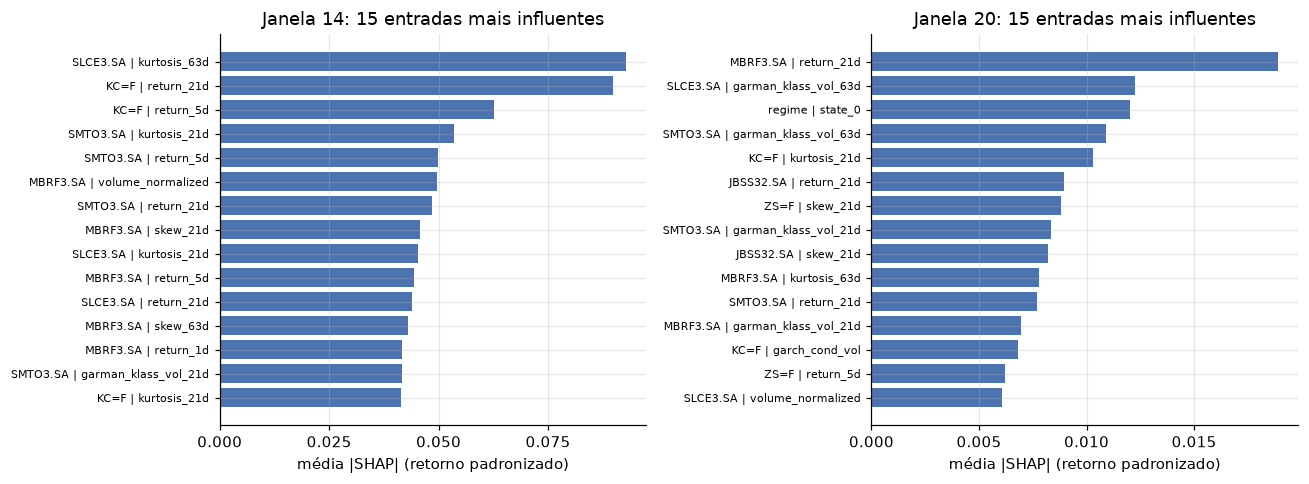

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (fold, imp) in zip(axes, tables.items()):
    top = imp.sort_values("importancia").tail(15)
    ax.barh(top.variavel, top.importancia, color="#4C72B0")
    ax.set_title(f"Janela {fold}: 15 entradas mais influentes")
    ax.set_xlabel("média |SHAP| (retorno padronizado)")
    ax.tick_params(axis="y", labelsize=7)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_shap_top_entradas.png", bbox_inches="tight")

## Quão longe no passado a rede olha

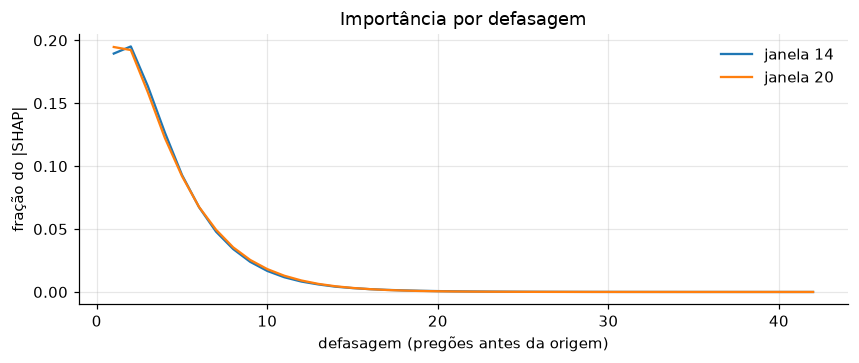

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for fold, result in results.items():
    by_lag = np.abs(result["values"]).sum(axis=2).mean(axis=0)[::-1]  # defasagem 1 = véspera
    ax.plot(np.arange(1, len(by_lag) + 1), by_lag / by_lag.sum(), label=f"janela {fold}")
ax.set_xlabel("defasagem (pregões antes da origem)")
ax.set_ylabel("fração do |SHAP|")
ax.set_title("Importância por defasagem")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_shap_por_defasagem.png", bbox_inches="tight")

## O regime no estresse

O notebook 05 mostrou que a HMM-LSTM prevê retorno positivo quando o HMM indica estresse. Se
o regime é a causa disso dentro da rede, a contribuição das colunas de regime deve ser
positiva nesses dias.

In [6]:
rows = []
for fold, result in results.items():
    regime_idx = [i for i, c in enumerate(result["columns"]) if c[0] == "regime"]
    other_idx = [i for i, c in enumerate(result["columns"]) if c[0] != "regime"]
    contrib = result["values"].sum(axis=1)  # por dia e entrada, somado no tempo
    for label, mask in (("estresse", result["stress"]), ("demais", ~result["stress"])):
        if mask.sum() == 0:
            continue
        rows.append({"janela": fold, "dias": label, "n": int(mask.sum()),
                     "SHAP do regime (média)": contrib[mask][:, regime_idx].sum(axis=1).mean(),
                     "SHAP das demais entradas (média)": contrib[mask][:, other_idx].sum(axis=1).mean()})
regime_effect = pd.DataFrame(rows).set_index(["janela", "dias"]).round(3)
regime_effect

n  SHAP do regime (média)  SHAP das demais entradas (média)
janela dias                                                                   
14     estresse   28                   0.015                             0.251
       demais     93                   0.004                             0.009
20     estresse   22                  -0.009                            -0.102
       demais    100                  -0.009                            -0.057

Os valores estão na escala do retorno padronizado do treino, em que 1 equivale a um desvio
padrão diário.

In [7]:
pd.concat({fold: imp.assign(janela=fold) for fold, imp in tables.items()}).to_csv(
    TABLES_DIR / "shap_importancia_por_entrada.csv", index=False)
regime_effect.to_csv(TABLES_DIR / "shap_efeito_regime.csv")
print("Tabelas salvas em", TABLES_DIR)

Tabelas salvas em C:\Python\hmm_lstm_TCC\reports\tables


## Leitura

- A rede se apoia em três grupos com pesos parecidos: retornos recentes, volatilidades e
  momentos de ordem superior (assimetria e curtose). Cada um responde por cerca de 30% da
  importância. Liquidez e volatilidade implícita pesam pouco.
- As entradas mais influentes mudam quase inteiramente de uma janela para outra (a curtose
  da SLC e os retornos do café na janela 14; o retorno de 21 dias da Marfrig e volatilidades
  na janela 20). Não há um conjunto estável de variáveis que a rede use em todo o período.
- **O regime do HMM tem participação pequena**: cerca de 1% na janela 14 e 4% na janela 20.
  A rede recebe a mesma informação, de forma mais detalhada, pelas próprias volatilidades,
  das quais o regime é um resumo.
- Na janela 14, a previsão média sobe nos dias de estresse (março de 2020), mas quase todo
  esse aumento vem das outras entradas, não das colunas de regime. A média mais alta da
  HMM-LSTM no estresse (notebook 05) não é, portanto, um efeito direto da coluna de regime.
  Ela parece decorrer de a rede ter sido treinada de outra forma ao receber mais entradas.
  Com cerca de 700 sequências de treino, diferenças assim entre duas redes podem ser em boa
  parte ruído de estimação. No estresse, a diferença de escore entre HMM-LSTM e LSTM não é
  significativa (notebook 06).
- O SHAP descreve a rede, não o mercado: uma variável influente para a rede não precisa ser
  causa da perda. Como a previsão de média não superou o retorno zero (notebook 04), estas
  explicações mostram o que a rede usa, não um sinal que tenha funcionado fora da amostra.